In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\vivek\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv("ecommerce_data.csv")

df.head()

,OrderDate,OrderID,Delivery Date,CustomerID,Customer Age,Customer Gender,Location,Zone,Delivery Type,Product Category,SubCategory,Product,Unit Price,Shipping Fee,Order Quantity,Sale Price,Status,Reason,Rating
0,31-05-2020,5136486,04-06-2020,230569424,57,M,Western,Zone 3,Express,Fashion,Girl's fashion,Fashion Girl's Dress Kids Children Newborn Bab...,147,10,2,196,Returned,Onsite -Description mismatch,2
1,31-05-2020,5136457,12-06-2020,230568182,24,F,Western,Zone 3,Standard Delivery,Health and beauty,Medical supplies and Equipment,Blood Pressure Monitor Digital Wrist BP Pulse ...,131,4,7,183,Returned,Product - Not fitting expectation,2
2,31-05-2020,5136465,10-06-2020,230567584,31,M,Weija,Zone 2,Standard Delivery,Health and beauty,Medical supplies and Equipment,Portable Blood Pressure Monitor - White,69,6,10,205,Delivered,NaN,3
3,31-05-2020,5136488,05-06-2020,230563788,62,F,Greater Accra,Zone 1,Express,Phones and Tablet,Mobile phones,Samsung A3 Core Dual SIM - 16GB HDD - 1GB RAM ...,148,7,7,291,Delivered,NaN,1
4,31-05-2020,5136449,10-06-2020,230563726,18,F,Weija,Zone 2,Shipped from Abroad,Fashion,Boy's fashion,Boys Sneakers Casual Kids Sports Shoes-Gold,126,12,9,260,Delivered,NaN,3


In [3]:
df.columns

Index(['OrderDate', 'OrderID', 'Delivery Date', 'CustomerID', 'Customer Age',
       'Customer Gender', 'Location', 'Zone', 'Delivery Type',
       'Product Category', 'SubCategory', 'Product', 'Unit Price',
       'Shipping Fee', 'Order Quantity', 'Sale Price', 'Status', 'Reason',
       'Rating'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113000 entries, 0 to 112999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   OrderDate         113000 non-null  str  
 1   OrderID           113000 non-null  int64
 2   Delivery Date     113000 non-null  str  
 3   CustomerID        113000 non-null  int64
 4   Customer Age      113000 non-null  int64
 5   Customer Gender   113000 non-null  str  
 6   Location          113000 non-null  str  
 7   Zone              113000 non-null  str  
 8   Delivery Type     113000 non-null  str  
 9   Product Category  113000 non-null  str  
 10  SubCategory       113000 non-null  str  
 11  Product           113000 non-null  str  
 12  Unit Price        113000 non-null  int64
 13  Shipping Fee      113000 non-null  int64
 14  Order Quantity    113000 non-null  int64
 15  Sale Price        113000 non-null  int64
 16  Status            113000 non-null  str  
 17  Reason            296

In [6]:
# convert dates
df['OrderDate'] = pd.to_datetime(df['OrderDate'], dayfirst=True)
df['Delivery Date'] = pd.to_datetime(df['Delivery Date'], dayfirst=True)

# remove duplicates
df = df.drop_duplicates()

print(df.head())

   OrderDate  OrderID Delivery Date  CustomerID  Customer Age Customer Gender  \
0 2020-05-31  5136486    2020-06-04   230569424            57               M   
1 2020-05-31  5136457    2020-06-12   230568182            24               F   
2 2020-05-31  5136465    2020-06-10   230567584            31               M   
3 2020-05-31  5136488    2020-06-05   230563788            62               F   
4 2020-05-31  5136449    2020-06-10   230563726            18               F   

        Location    Zone        Delivery Type   Product Category  \
0        Western  Zone 3              Express            Fashion   
1        Western  Zone 3    Standard Delivery  Health and beauty   
2          Weija  Zone 2    Standard Delivery  Health and beauty   
3  Greater Accra  Zone 1              Express  Phones and Tablet   
4          Weija  Zone 2  Shipped from Abroad            Fashion   

                      SubCategory  \
0                  Girl's fashion   
1  Medical supplies and Equipm

In [9]:
import pandas as pd

# load dataset
df = pd.read_csv("Ecommerce_data.csv")

# check columns first
print(df.columns)

# convert date columns
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')
df['Delivery Date'] = pd.to_datetime(df['Delivery Date'], errors='coerce')

# remove duplicates
df = df.drop_duplicates()

# remove cancelled orders
df = df[df['Status'] != 'Cancelled']

# dataset info
print("Shape:", df.shape)
print(df.head())
print(df.info())

Index(['OrderDate', 'OrderID', 'Delivery Date', 'CustomerID', 'Customer Age',
       'Customer Gender', 'Location', 'Zone', 'Delivery Type',
       'Product Category', 'SubCategory', 'Product', 'Unit Price',
       'Shipping Fee', 'Order Quantity', 'Sale Price', 'Status', 'Reason',
       'Rating'],
      dtype='str')
Shape: (113000, 19)
   OrderDate  OrderID Delivery Date  CustomerID  Customer Age Customer Gender  \
0 2020-05-31  5136486    2020-04-06   230569424            57               M   
1 2020-05-31  5136457    2020-12-06   230568182            24               F   
2 2020-05-31  5136465    2020-10-06   230567584            31               M   
3 2020-05-31  5136488    2020-05-06   230563788            62               F   
4 2020-05-31  5136449    2020-10-06   230563726            18               F   

        Location    Zone        Delivery Type   Product Category  \
0        Western  Zone 3              Express            Fashion   
1        Western  Zone 3    Standard 

C:\Users\vivek\AppData\Local\Temp\ipykernel_7928\707735320.py:10: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')


In [10]:
df['Revenue'] = df['Sale Price'] * df['Order Quantity']

print("Total Revenue:", df['Revenue'].sum())

Total Revenue: 135611346


KPIs Matrics

In [11]:
total_orders = df['OrderID'].nunique()
total_customers = df['CustomerID'].nunique()
avg_order_value = df['Revenue'].mean()

print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", avg_order_value)

Total Orders: 113000
Total Customers: 113000
Average Order Value: 1200.100407079646


Revenue Trend Analysis (Monthly)

In [12]:
# create month column
df['Month'] = df['OrderDate'].dt.to_period('M')

# revenue by month
monthly_revenue = df.groupby('Month')['Revenue'].sum().reset_index()

print(monthly_revenue)

      Month  Revenue
0   2015-01  1760681
1   2015-02  1627438
2   2015-03  1646736
3   2015-04  1795465
4   2015-05  1811726
..      ...      ...
67  2020-08  1705238
68  2020-09  1782965
69  2020-10  1783067
70  2020-11  1722351
71  2020-12  1824260

[72 rows x 2 columns]


visuals

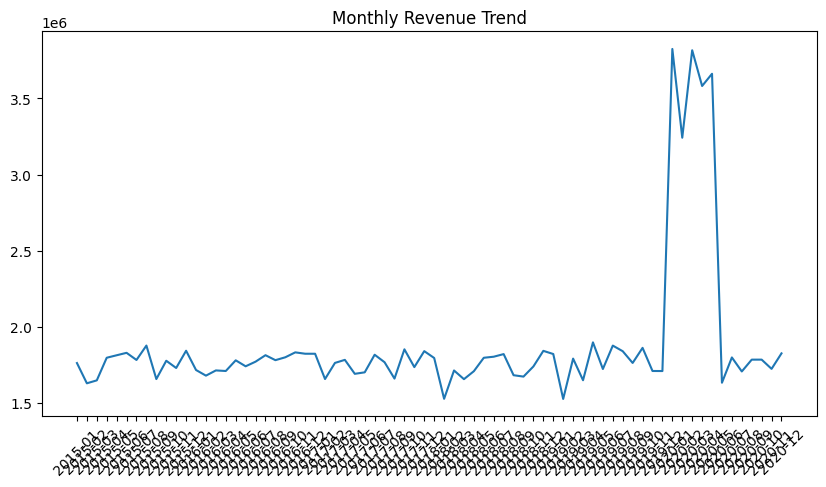

In [13]:
import matplotlib.pyplot as plt

monthly_revenue['Month'] = monthly_revenue['Month'].astype(str)

plt.figure(figsize=(10,5))
plt.plot(monthly_revenue['Month'], monthly_revenue['Revenue'])
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.show()

In [14]:
category_sales = df.groupby('Product Category')['Revenue'].sum().sort_values(ascending=False)

print(category_sales)

Product Category
Health and beauty    44717534
Fashion              41298021
Phones and Tablet    22322776
Home and Office      19163611
Electronics           8109404
Name: Revenue, dtype: int64


In [15]:
top_products = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False).head(10)

print(top_products)

Product
Avon Soft Musk Eau de Toilette Spray - 50ml                                                               3258971
Triple Power C20 Super Bass USB Bluetooth Subwoofer - Brown + free S530 V4.0 Bluetooth Headset - Black    3244843
Yazole Leather Wrist Watch - Black                                                                        3240080
Blood Pressure Monitor Digital Wrist BP Pulse Monitor Meter Heart Rate Measure                            3233122
Fashion 4-Piece Leather HandBag Set - Black                                                               3232140
Fashion Girls' Patent Leather Stitching Shoes - Black                                                     3231432
10.1'' Business Tablet with MT6582 Quad-Core Processor                                                    3227724
B5 HiFi 5.0 Ture Wireless Headsets Auto Pair Touch - Black                                                3224708
Plastic Storage Bowl - 17 Pieces Green                                          

Customer Retention analysis

In [16]:
first_purchase = df.groupby('CustomerID')['OrderDate'].min().reset_index()
first_purchase.columns = ['CustomerID','FirstPurchaseDate']

In [17]:
df = df.merge(first_purchase, on='CustomerID')

In [18]:
repeat_customers = df.groupby('CustomerID')['OrderID'].nunique()

retained = (repeat_customers > 1).sum()
total = repeat_customers.count()

retention_rate = retained / total * 100

print("Customer Retention Rate:", retention_rate)

Customer Retention Rate: 0.0


Location Revenue Analysis

In [19]:
location_revenue = df.groupby('Location')['Revenue'].sum().sort_values(ascending=False)

print(location_revenue)

Location
Greater Accra    34171505
Ashanti          28591623
Western          21444033
Weija            16334591
Upper West        6729676
Volta             6057132
Upper East        4067931
Prampram          2874744
Savannah          2747403
Oyarifa           1794682
Oti               1694000
Northern          1444313
North East        1312155
Kitase            1107465
Kasoa              919892
Dodowa             782529
Gbawe              686574
Eastern            666075
Western North      507532
Brong-Ahafo        505154
Bono               464211
Ahafo              231757
Amasaman           209411
Central            159396
Dawhenya            99674
Bono East            7888
Name: Revenue, dtype: int64


In [20]:
df.to_csv("cleaned_ecommerce_data.csv", index=False)

In [9]:
import pandas as pd

df = pd.read_csv("../data/Ecommerce_Data.csv")

# convert date column
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# RFM calculation
rfm = df.groupby('CustomerID').agg({
    'OrderDate': lambda x: (df['OrderDate'].max() - x.max()).days,  # Recency
    'OrderID': 'count',                                             # Frequency
    'Sale Price': 'sum'                                             # Monetary
})

rfm.columns = ['Recency','Frequency','Monetary']

rfm.head()

C:\Users\vivek\AppData\Local\Temp\ipykernel_18524\3115578019.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['OrderDate'] = pd.to_datetime(df['OrderDate'])


,Recency,Frequency,Monetary
CustomerID,,,
230459067,1895,1,248
230459068,1287,1,275
230459069,983,1,170
230459072,355,1,266
230459073,75,1,156


In [10]:
rfm['R_score'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method="first"), 4, labels=[1,2,3,4])
rfm['M_score'] = pd.qcut(rfm['Monetary'], 4, labels=[1,2,3,4])

rfm['RFM_Score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

rfm.head()

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
CustomerID,,,,,,,
230459067,1895,1,248,1,1,3,113
230459068,1287,1,275,2,1,4,214
230459069,983,1,170,3,1,1,311
230459072,355,1,266,4,1,4,414
230459073,75,1,156,4,1,1,411


In [11]:
def segment(row):
    
    if row['RFM_Score'] == '444':
        return 'Champions'
    
    elif row['F_score'] >= 3 and row['M_score'] >= 3:
        return 'Loyal Customers'
    
    elif row['R_score'] >= 3:
        return 'Potential Loyalists'
    
    elif row['R_score'] == 1:
        return 'Lost Customers'
    
    else:
        return 'Regular Customers'

rfm['CustomerSegment'] = rfm.apply(segment, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,CustomerSegment
CustomerID,,,,,,,,
230459067,1895,1,248,1,1,3,113,Lost Customers
230459068,1287,1,275,2,1,4,214,Regular Customers
230459069,983,1,170,3,1,1,311,Potential Loyalists
230459072,355,1,266,4,1,4,414,Potential Loyalists
230459073,75,1,156,4,1,1,411,Potential Loyalists


In [12]:
rfm['CustomerSegment'].value_counts()

CustomerSegment
Potential Loyalists    42566
Loyal Customers        26301
Regular Customers      21265
Lost Customers         21122
Champions               1746
Name: count, dtype: int64

In [13]:
rfm.to_csv("../data/rfm_customer_segments.csv")